### 导入所需的库

In [1]:
import gc
import cv2
import torch
import torchvision
import numpy as np
import torch.nn.functional as F
import torchvision.transforms.functional as VF
import matplotlib.pyplot as plt
import ipywidgets as widgets

from tqdm import tqdm
from PIL import Image
from matplotlib import font_manager
from skimage import transform as trans
from torchmetrics.image import TotalVariation

from arcface.iresnet import iresnet50
from mtcnn.src import detect_faces, show_bboxes
from mtcnn.src.get_nets import PNet, RNet, ONet

### 导入中文字体

In [2]:
font_path = "assets/fonts/simhei.ttf"
font_manager.fontManager.addfont(font_path)
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

### 设置计算设备，如果有GPU加速器则使用加速器计算

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"

### 加载人脸识别模型

In [4]:
pnet = PNet()
pnet.to(device)
rnet = RNet()
rnet.to(device)
onet = ONet()
onet.to(device)
print("人脸识别模型加载完成")

人脸识别模型加载完成


### 查看源人脸图片和目标人脸图片
1. 攻击者提供源人脸图片，受害者提供目标人脸图片
2. 根据上传的图片名称修改``Image.open``的参数

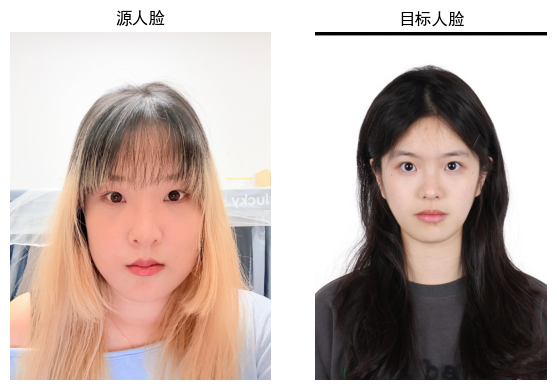

In [6]:
source_image = Image.open("source.jpg")
target_image = Image.open("target.jpg")

# target_image = Image.open("Source.jpg")
# source_image = Image.open("Target.jpg")

fig, axes = plt.subplots(1, 2, figsize=(6, 4))

axes[0].imshow(np.array(source_image))
axes[0].axis('off')
axes[0].set_title('源人脸')

axes[1].imshow(np.array(target_image))
axes[1].axis('off')
axes[1].set_title('目标人脸')

fig.tight_layout()
plt.show()
plt.close(fig)

### 人脸检测

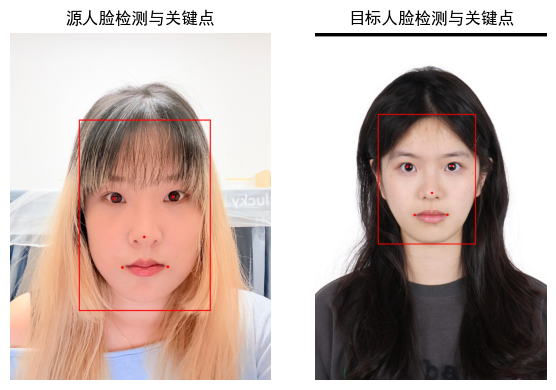

In [7]:
bounding_boxes, source_image_landmarks = detect_faces(source_image, pnet, rnet, onet, device)
marked_source_image = show_bboxes(source_image, bounding_boxes, source_image_landmarks)
bounding_boxes, target_image_landmarks = detect_faces(target_image, pnet, rnet, onet, device)
marked_target_image = show_bboxes(target_image, bounding_boxes, target_image_landmarks)

del pnet, rnet, onet
gc.collect()
torch.cuda.empty_cache()

fig, axes = plt.subplots(1, 2, figsize=(6, 4))

axes[0].imshow(np.array(marked_source_image))
axes[0].axis('off')
axes[0].set_title('源人脸检测与关键点')

axes[1].imshow(np.array(marked_target_image))
axes[1].axis('off')
axes[1].set_title('目标人脸检测与关键点')

fig.tight_layout()
plt.show()
plt.close(fig)

In [8]:
# Align face as ArcFace template
def face_align(img, landmarks):
    image_size = [600,600]
    src = 600./112.*np.array([
        [38.2946, 51.6963],
        [73.5318, 51.5014],
        [56.0252, 71.7366],
        [41.5493, 92.3655],
        [70.7299, 92.2041] ], dtype=np.float32)
    dst = landmarks.astype(np.float32)
    tform = trans.SimilarityTransform.from_estimate(dst, src)
    M = tform.params[0:2,:]

    warped = cv2.warpAffine(img, M, (image_size[1],image_size[0]), borderValue = 0.0)
    return warped

(600, 600, 3)
(600, 600, 3)


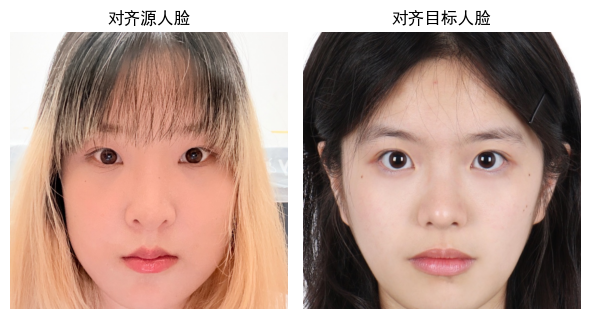

In [9]:
# 选择第一个检测到的人脸
first_source_image_landmarks = source_image_landmarks[0, :]
first_source_image_landmarks = first_source_image_landmarks.reshape((2, 5)).T
aligned_source_image = face_align(np.array(source_image), first_source_image_landmarks)
print(aligned_source_image.shape)

first_target_image_landmarks = target_image_landmarks[0, :]
first_target_image_landmarks = target_image_landmarks.reshape((2, 5)).T
aligned_target_image = face_align(np.array(target_image), first_target_image_landmarks)
print(aligned_target_image.shape)

fig, axes = plt.subplots(1, 2, figsize=(6, 4))

axes[0].imshow(np.array(aligned_source_image))
axes[0].axis('off')
axes[0].set_title('对齐源人脸')

axes[1].imshow(np.array(aligned_target_image))
axes[1].axis('off')
axes[1].set_title('对齐目标人脸')

fig.tight_layout()
plt.show()
plt.close(fig)

In [10]:
aligned_source_image_tensor = VF.to_tensor(aligned_source_image).unsqueeze(0)
aligned_target_image_tensor = VF.to_tensor(aligned_target_image).unsqueeze(0)

In [11]:
def parabola_length(x, a):
    return 0.5 * x * (1 + 4 * a * a *  x * x).sqrt() + \
    1. / (4 * a) * torch.log(
        2 * a * x + (1 + 4 * a * a *  x * x).sqrt()
    )


def projector(sticker, a, alpha):
    '''Apply off-plane transformations to the sticker images
    a: parabola rate of the off-plane parabolic tranformation, rank 1 tensor with shape [N]
    theta: angle of the off-plane rotation, rank 1 tensor with shape [N]
    sticker: rank 4 tensor with format NCHW and shape [N, C, H, W]
    
    return: rank 4 tensor with format NCHW and shape [N, C, H, W]
    '''
    device = sticker.device
    #############################################################################################################
    # parabolic tranformation
    width = sticker.shape[-1]
    half_width = width // 2
    height = sticker.shape[-2]
    assert width > height

    right_cumsum = torch.cumsum(sticker[..., half_width:], dim=-1)
    left_cumsum = torch.cumsum(sticker[..., :half_width].flip([-1]), dim=-1)

    right_cumsum = F.pad(right_cumsum, (1, 0), "constant", 0.)
    left_cumsum = F.pad(left_cumsum, (1, 0), "constant", 0.)

    anchors = parabola_length(
        torch.arange(0, half_width + 1, dtype=torch.float32, device=device).unsqueeze(0), 
        a.unsqueeze(1)
    )
    anchors = anchors.clamp(0, half_width).round()

    anchors = anchors[:, None, None, :].expand_as(right_cumsum)

    anchors_diff = anchors[..., 1:] - anchors[..., :-1]

    anchors = anchors.long()
    right_cumsum_sample = torch.gather(right_cumsum, -1, anchors)
    left_cumsum_sample = torch.gather(left_cumsum, -1, anchors)
    right_diff = right_cumsum_sample[..., 1:] - right_cumsum_sample[..., :-1]
    left_diff = left_cumsum_sample[..., 1:] - left_cumsum_sample[..., :-1]
    right = right_diff / (anchors_diff + 1e-6)
    left = left_diff / (anchors_diff + 1e-6)

    sticker = torch.cat([left.flip([-1]), right], dim=-1)
    #############################################################################################################

    #############################################################################################################
    # rotation
    cumsum = torch.cumsum(sticker, dim=2)
    cumsum = F.pad(cumsum, (1, 0, 0, 0), "constant", 0.)
    alpha = np.pi / 180. * alpha
    alpha = alpha[-1, None, None, None]

    x = torch.arange(width + 1, dtype = torch.float32, device=device) - width / 2.
    z = a.unsqueeze(1) * x.unsqueeze(0) ** 2 # N x W
    pad_size = (width - height) // 2
    y = torch.arange(width+1, dtype = torch.float32, device=device) - pad_size
    y_prev = (y[None, None, :, None] - z[:, None, None, :] * torch.sin(alpha)) / torch.cos(alpha) # N x W
    y_prev = y_prev.clamp(0, height - 1).round()
    y_div = y_prev[:, :, 1:] - y_prev[:, :, :-1]

    indices = y_prev.expand(-1, 3, -1, width + 1)
    indices = indices.long()
    cumsum_sample = torch.gather(cumsum, 2, indices)
    cumsum_diff = cumsum_sample[:, :, 1:, :] - cumsum_sample[:, :, :-1, :]
    sticker = cumsum_diff / (y_div + 1e-6)
    sticker = sticker.clamp(0, 1)[..., :-1]
    #############################################################################################################

    return sticker


def stn(x, alpha, dx, dy, scale, size=None):
    alpha = np.pi / 180. * alpha
    scale = scale[:, None, None]
    theta_row1 = torch.stack([alpha.cos(), alpha.sin(), -dx], dim=1)
    theta_row2 = torch.stack([-alpha.sin(), alpha.cos(), -dy], dim=1)
    theta = 1. / scale * torch.stack([theta_row1, theta_row2], dim=1)
    if size is None:
        affine_grid_points = F.affine_grid(theta, x.size(), align_corners=True)
    else:
        affine_grid_points = F.affine_grid(theta, size, align_corners=True)
    result = F.grid_sample(x, affine_grid_points, align_corners=True)

    return result

In [12]:
mask_height = 300
mask_width = 600

def mask_transform(a, alpha, dx, dy, scale):
    a = torch.tensor([a])
    alpha = torch.tensor([alpha])
    dx = torch.tensor([dx])
    dy = torch.tensor([dy])
    scale = torch.tensor([scale])
    
    mask = torch.ones(1, 3, mask_height, mask_width)
    
    mask = projector(mask, a, alpha)
    mask = stn(mask, torch.tensor([0]), dx, dy, scale)

    united = aligned_source_image_tensor * (1 - mask) + mask
    united = united.clamp(0, 1).mul(255).to(torch.uint8)[0].permute(1, 2, 0)
    
    plt.imshow(united)
    plt.axis('off')
    plt.show()

style = {'description_width': 'initial'}
widgets.interact(
    mask_transform,
    a=widgets.FloatSlider(
        value=0.001, min=0.0001, max=0.005, step=0.0001,
        description='抛物线系数-a', readout_format='.4f',
        continuous_update=False, style=style),
    alpha=widgets.FloatSlider(
        value=0, min=-30, max=30, step=0.1,
        description='旋转角度-alpha', readout_format='.1f',
        continuous_update=False, style=style),
    dx=widgets.FloatSlider(
        value=0, min=-0.2, max=0.2, step=1./(mask_width/2),
        description='水平位移-dx', readout_format='.3f',
        continuous_update=False, style=style),
    dy=widgets.FloatSlider(
        value=0, min=-1.0, max=1.0, step=1./(mask_width/2),
        description='垂直位移-dy', readout_format='.3f',
        continuous_update=False, style=style),
    scale=widgets.FloatSlider(
        value=1.0, min=0.01, max=1.0, step=0.005,
        description='缩放比例-scale', readout_format='.3f',
        continuous_update=False, style=style),
);

interactive(children=(FloatSlider(value=0.001, continuous_update=False, description='抛物线系数-a', max=0.005, min=…

In [13]:
a = torch.tensor([0.0016])
alpha = torch.tensor([-6.3])
dx = torch.tensor([0.04])
dy = torch.tensor([0.557])
scale = torch.tensor([0.710])

In [14]:
def random_apply_sticker(host, sticker, a, alpha, dx, dy, scale, batch_size=16):
    device = host.device

    height, width = sticker.shape[-2:]
    
    host = host.expand(batch_size, -1, -1, -1)
    sticker = sticker.expand(batch_size, -1, -1, -1)

    a = (torch.rand(batch_size, device=device) * 2 - 1) * 0.0002 + a
    alpha = (torch.rand(batch_size, device=device) * 2 - 1) * 2 + alpha

    alpha1 = (torch.rand(batch_size, device=device) * 2 - 1) * 10
    scale1 = (torch.rand(batch_size, device=device) * 2 - 1) * 0.02 + scale
    dx1 = (torch.rand(batch_size, device=device) * 2 - 1) * 0.02 + dx
    dy1 = (torch.rand(batch_size, device=device) * 2 - 1) * 0.02 + dy

    alpha2 = (torch.rand(batch_size, device=device) * 2 - 1) * 10
    scale2 = torch.rand(batch_size, device=device) * (1.04 - 1./1.04) + 1./1.04
    dx2 = torch.zeros(batch_size, device=device)
    dy2 = (torch.rand(batch_size, device=device) * 2 - 1) * 0.02

    mask = torch.ones_like(sticker, device=device)
    mask = stn(projector(mask, a, alpha), alpha1, dx1, dy1, scale1)

    sticker = stn(projector(sticker, a, alpha), alpha1, dx1, dy1, scale1)

    united = sticker * mask + host * (1 - mask)

    result = stn(united, alpha2, dx2, dy2, scale2, (batch_size, 3, 112, 112))
    result = torch.clamp(result, 0., 1.)

    return result

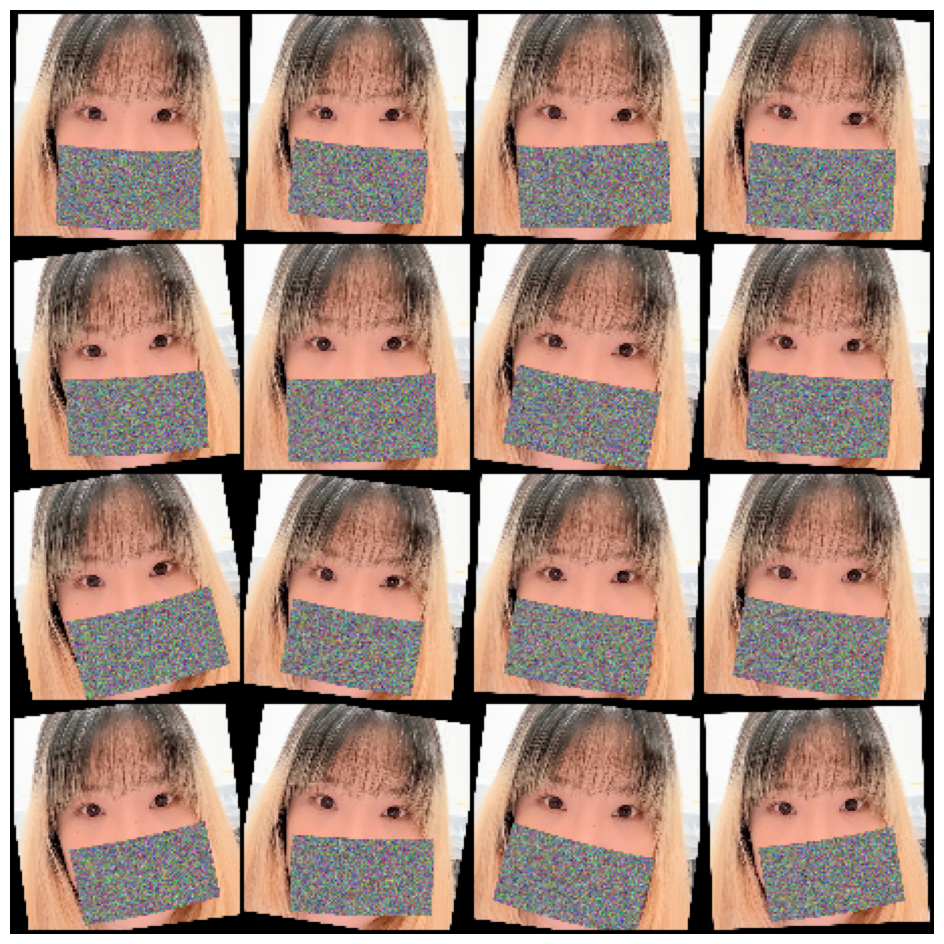

In [15]:
sticker = torch.rand(1, 3, mask_height, mask_width)

random_batch = random_apply_sticker(
    aligned_source_image_tensor,
    sticker,
    a, alpha, dx, dy, scale
)

grid = torchvision.utils.make_grid(random_batch, nrow=4, padding=2, normalize=False)
npimg = grid.permute(1, 2, 0).cpu().numpy()

plt.figure(figsize=(12, 12))
plt.imshow(npimg)
plt.axis('off')
plt.show()

In [16]:
@torch.amp.autocast("cuda")
def optimize_sticker(
    sticker, aligned_source_image_tensor, aligned_target_image_tensor,
    total_steps=500, moment=0.9, step_size=2./255
):
    aligned_target_image_tensor = VF.resize(aligned_target_image_tensor, [112, 112])

    sticker.requires_grad_(True).to(device)

    model = iresnet50()
    model.load_state_dict(torch.load("arcface/backbone.pth"))
    model.to(device).eval().requires_grad_(False)

    with torch.no_grad():
        aligned_target_image_tensor.sub_(0.5).div_(0.5)
        target_emb = model(aligned_target_image_tensor)
        target_emb = F.normalize(target_emb, dim=-1)

    tv_loss_fn = TotalVariation("sum").to(device)
    
    accum_grads = torch.zeros_like(sticker, device=device)
    pbar = tqdm(range(total_steps), desc='优化贴纸')
    for step in pbar:
        if sticker.grad is not None:
            sticker.grad.zero_()

        batch = random_apply_sticker(
            aligned_source_image_tensor,
            sticker,
            a, alpha, dx, dy, scale
        )

        batch = batch.sub(0.5).div(0.5)

        embs = model(batch)
        embs = F.normalize(embs, dim=-1)

        cos_loss = 1 - (embs * target_emb).sum(dim=-1).mean()

        tv_loss = 1e-4 * tv_loss_fn(sticker)

        loss = cos_loss + tv_loss
        
        loss.backward()

        grad = sticker.grad

        accum_grads = accum_grads * moment + grad * (1 - moment)

        with torch.no_grad():
            sticker -= step_size * torch.sign(accum_grads)
            sticker = sticker.clamp(0, 1)

        sticker = sticker.detach().requires_grad_(True)

        metrics = {
            "Step": step,
            "Sim to Target": f"{1 - cos_loss.item():.2f}",
            "TV Loss": f"{tv_loss.item():.2f}"
        }
        pbar.set_postfix(metrics)

    return sticker

In [19]:
a = torch.tensor([0.0016])
alpha = torch.tensor([-6.3])
dx = torch.tensor([0.04])
dy = torch.tensor([0.557])
scale = torch.tensor([0.710])
a = a.to(device)
alpha = alpha.to(device)
dx = dx.to(device)
dy = dy.to(device)
scale = scale.to(device)
aligned_source_image_tensor = aligned_source_image_tensor.to(device)
aligned_target_image_tensor = aligned_target_image_tensor.to(device)
sticker = torch.rand(1, 3, mask_height, mask_width, device=device)

In [20]:
sticker = optimize_sticker(
    sticker, aligned_source_image_tensor, aligned_target_image_tensor,
    total_steps=500, moment=0.9, step_size=5./255
)
torchvision.utils.save_image(sticker, "sticker.png")
print("完成！")

优化贴纸: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 500/500 [00:13<00:00, 36.01it/s, Step=499, Sim to Target=0.72, TV Loss=2.74]


完成！
